# LOF Experimentation 

Key metrics that will be evaluated for this analysis 
1. **ROC-AUC**: how often the model scores a random fraud transaction higher than a random normal one (0.5 = random guessing, 1 = perfect).
2. **PR-AUC**: how “clean” the top of the ranked list stays as you catch more fraud, where random guessing scores about the fraud rate (0.035).
3. **Precision @ 3.5%**: of the transactions in the top 3.5% most anomalous, the share that are actually fraud.
4. **Recall @ 3.5%**: of all the fraud in the data, the share that shows up in the top 3.5% most anomalous.

In preparation of the model evaluations, the following set up includes required models from python libraries and creating unlabeled training data.

In [1]:
# TASK 5 PART TWO ---------------------------------------

#import Local Outlier Factor
from sklearn.neighbors import LocalOutlierFactor

from IPython.display import display
import time
from sklearn.metrics import roc_auc_score, average_precision_score
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Label Data Files
train_transaction = pd.read_csv("Data/train_transaction.csv")
train_identity = pd.read_csv("Data/train_identity.csv")

# Merging two databse by identity id by creating a new dataframe
df = train_transaction.merge(train_identity, on="TransactionID", how="left")

### 3.1 E0 Baseline Model
The Local Outlier Factor (LOF) baseline model was fitted with scikit-learn's default parameters (`n_neighbors = 20`). Because LOF compares every transaction with its nearest neighbours, fitting all 590,540 transactions would take around 2 hours, so a random subsample of 25,000 transactions (`random_state = 100`) was used instead. The model was trained on the same features as the Isolation Forest baseline, with `isFraud` withheld.

To evaluate performance, the distribution of LOF scores was plotted, ROC-AUC and PR-AUC were calculated, and the labels were checked for both the top 10 and the top 3.5% most anomalous transactions.


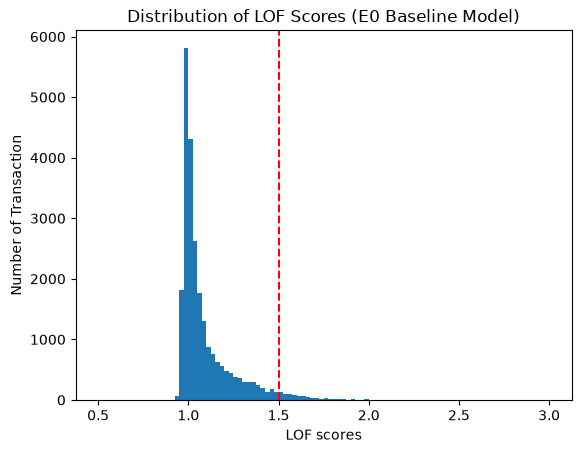

,TransactionAmt,ProductCD,card4,card6,LOF_Score,isFraud
581436,30.000,S,mastercard,credit,28.098612,0
168376,50.000,H,mastercard,debit,13.235140,0
177516,100.000,H,visa,credit,12.222669,0
170507,50.000,H,visa,debit,11.895096,0
547816,165.000,S,mastercard,credit,11.894325,0
...,...,...,...,...,...,...
465839,75.000,H,visa,debit,1.533173,0
574817,22.440,C,visa,credit,1.533155,0
463164,16.846,C,mastercard,debit,1.533146,0
433674,40.000,H,mastercard,debit,1.533123,0


Number of Actual Fraud in top 3.5% (875 transactions From LOF): 73


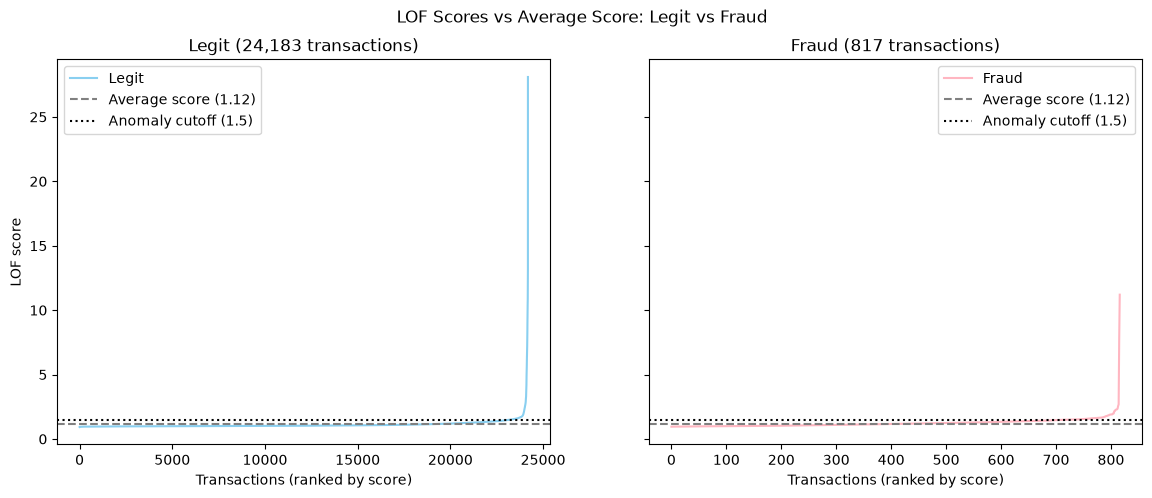

ROC-AUC: 0.686
PR-AUC: 0.068
Precision @ 3.5%: 8.3%
Recall @ 3.5%: 8.9%
Runtime: 4.4s


In [ ]:
# Only keeping 25 000 transaction due to the run time of the model
df = df.sample(n=25000, random_state=100)

# Database used for learning
# + only uses col that have numbers (don't want categorical)
# fill in empty cells
newdf = df[train_transaction.columns].drop(columns="isFraud").select_dtypes(include="number").fillna(-999)

# Results table for every experiment in Part 2 (one row per experiment)
all_results = pd.DataFrame(columns=["ROC-AUC", "PR-AUC", "Processing Time (s)"], dtype=float)

# E0: LOF Baseline Model (n_neighbors=20)
start_time = time.perf_counter() # start time
lof = LocalOutlierFactor() # Automatically sets n_neighbors=20
lof.fit_predict(newdf) # fit model
end_time = time.perf_counter() # end time

# temporary df for E0 analysis 
tempdf = df.copy()
tempdf["LOF_Score"] = - lof.negative_outlier_factor_ # add LOF score to temp df (flipped backwards because LOF score is a negative number)


# Similar Methodology as Isolation forest---------

#finding the dirstribution of the anomaly scores
# higher anomaly score = isolated in few splits = unusual
# anomaly score > 1.5 #anomaly 
tempdf["LOF_Score"].plot(kind="hist", bins=100, range = (0.5, 3), # because only 2 data point sits outside of this range, thus only consider (0.5,3) for visualization
                     title = "Distribution of LOF Scores (E0 Baseline Model)",
                     xlabel = "LOF scores",
                     ylabel = "Number of Transaction")
plt.axvline(1.5, color="red", linestyle="--", label="Anomaly cutoff (1.5)") #added cutoff 
plt.show()



#Diaply the Top 3.5% most anomalous transactions
top = 0.035
k = int(top * len(tempdf))
top_k = tempdf.sort_values("LOF_Score", ascending=False).head(k)
display(top_k[["TransactionAmt", "ProductCD", "card4", "card6", "LOF_Score", "isFraud"]])
print(f"Number of Actual Fraud in top 3.5% ({k} transactions From LOF): {top_k['isFraud'].sum()}")  




# Scatter: how far the anomalous transactions (score > 1.5) are from the average score
mean_score = tempdf["LOF_Score"].mean()
anomalous = tempdf.sort_values("LOF_Score").reset_index(drop=True)
anom_legit = anomalous[anomalous["isFraud"] == 0]
anom_fraud = anomalous[anomalous["isFraud"] == 1]

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)

# rank each group on its own (0 = lowest score) so each line spans its full chart
axes[0].plot(range(len(anom_legit)), anom_legit["LOF_Score"], color="#89CFF0", label="Legit")
axes[0].set_title(f"Legit ({len(anom_legit):,} transactions)")
axes[1].plot(range(len(anom_fraud)), anom_fraud["LOF_Score"], color="#FFB6C1", label="Fraud")
axes[1].set_title(f"Fraud ({len(anom_fraud):,} transactions)")

for ax in axes:
    ax.axhline(mean_score, color="grey", linestyle="--", label=f"Average score ({mean_score:.2f})")
    ax.axhline(1.5, color="black", linestyle=":", label="Anomaly cutoff (1.5)")
    ax.set_xlabel("Transactions (ranked by score)")
    ax.legend()
axes[0].set_ylabel("LOF score")

fig.suptitle("LOF Scores vs Average Score: Legit vs Fraud")
plt.show()
# E0 baseline results (uses tempdf, top_k and k from the cell above)
frauds_caught = top_k["isFraud"].sum()

print(f"ROC-AUC: {roc_auc_score(tempdf['isFraud'], tempdf['LOF_Score']):.3f}")
print(f"PR-AUC: {average_precision_score(tempdf['isFraud'], tempdf['LOF_Score']):.3f}")
print(f"Precision @ 3.5%: {frauds_caught / k:.1%}")
print(f"Recall @ 3.5%: {frauds_caught / tempdf['isFraud'].sum():.1%}")
print(f"Runtime: {end_time - start_time:.1f}s")


### 3.2 E1 Evaluating Contamination Parameter
Findings: The contamination parameter does not improve the metrics because it only changes the number of transactions flagged and setting the decision threshold rather than how transactions are scored. 

In [ ]:
# Only keeping 25 000 transaction due to the run time of the model
df = df.sample(n=25000, random_state=100)

# fill in empty cells with the median of the column
newdf = df[train_transaction.columns].drop(columns="isFraud").select_dtypes(include="number").fillna(-999)

# Contamination values that will be tested
neighbor_values = [20]
contamination_values = [0.01, 0.035, 0.05, 0.1]

# number of transactions in the top 3.5%
k = int(0.035 * len(df))

for j in contamination_values:

    for n in neighbor_values:
        # fit the model, timing it
        e1_start = time.perf_counter()
        e1_lof = LocalOutlierFactor(n_neighbors=n, contamination=j, n_jobs=-1)
        e1_labels = e1_lof.fit_predict(newdf) # -1 = flagged as anomaly, 1 = normal
        e1_end = time.perf_counter()

        # temporary df for this model (separate from the baseline's tempdf)
        e1df = df.copy()
        e1df["LOF_Score"] = -e1_lof.negative_outlier_factor_

        # top 3.5% most anomalous transactions
        e1_top_k = e1df.sort_values("LOF_Score", ascending=False).head(k)
        e1_frauds_caught = e1_top_k["isFraud"].sum()

        print(f"--- contamination = {j}, n_neighbors = {n} ---")
        print(f"Transactions Flagged: {(e1_labels == -1).sum()}")
        print(f"ROC-AUC: {roc_auc_score(e1df['isFraud'], e1df['LOF_Score']):.3f}")
        print(f"PR-AUC: {average_precision_score(e1df['isFraud'], e1df['LOF_Score']):.3f}")
        print(f"Precision @ 3.5%: {e1_frauds_caught / k:.1%}")
        print(f"Recall @ 3.5%: {e1_frauds_caught / e1df['isFraud'].sum():.1%}")
        print(f"Runtime: {e1_end - e1_start:.1f}s")

--- contamination = 0.01, n_neighbors = 20 ---
Transactions Flagged: 250
ROC-AUC: 0.686
PR-AUC: 0.068
Precision @ 3.5%: 8.3%
Recall @ 3.5%: 8.9%
Runtime: 4.6s
--- contamination = 0.035, n_neighbors = 20 ---
Transactions Flagged: 875
ROC-AUC: 0.686
PR-AUC: 0.068
Precision @ 3.5%: 8.3%
Recall @ 3.5%: 8.9%
Runtime: 4.6s
--- contamination = 0.05, n_neighbors = 20 ---
Transactions Flagged: 1250
ROC-AUC: 0.686
PR-AUC: 0.068
Precision @ 3.5%: 8.3%
Recall @ 3.5%: 8.9%
Runtime: 4.7s
--- contamination = 0.1, n_neighbors = 20 ---
Transactions Flagged: 2500
ROC-AUC: 0.686
PR-AUC: 0.068
Precision @ 3.5%: 8.3%
Recall @ 3.5%: 8.9%
Runtime: 4.8s


### 3.3 E2 n_neighbors value sensitivity (with filling missing data as -999)
n_neighbors control how crowded a transaction's surroundings are (sets how many nearby transaction count as "surroundings")

Findings: 
- As n_neighbors value increases ROC-AUC, PR-AUC, precision @ 3.5% and recall @ 3.5% decreases. This can be because as n_neighbors increases, LOF considers a larger group of transactions, including ones that may not be very similar to the transaction being evaluated, making it harder to find local unusual patterns. 
- Given that replacing missing data with -999 method was used, increasing n_neighbors can pushes the model to focus more on the missing value patterns rather than actual fraudulent behaviour.

In [7]:
# Only keeping 25 000 transaction due to the run time of the model
df = df.sample(n=25000, random_state=100)

# fill in empty cells with the median of the column
newdf = df[train_transaction.columns].drop(columns=["isFraud"]).select_dtypes(include="number").fillna(-999)
# newdf = newdf.fillna(newdf.median())

# n_neighbors values that will be tested
neighbor_values = [20, 100, 200, 3000]

for n in neighbor_values:
    # fit the model, timing it
    e1_start = time.perf_counter()
    e1_lof = LocalOutlierFactor(n_neighbors=n, n_jobs=-1)
    e1_lof.fit_predict(newdf)
    e1_end = time.perf_counter()

    # temporary df for this model (separate from the baseline's tempdf)
    e1df = df.copy()
    e1df["LOF_Score"] = -e1_lof.negative_outlier_factor_

    # top 3.5% most anomalous transactions
    e1_top_k = e1df.sort_values("LOF_Score", ascending=False).head(k)
    e1_frauds_caught = e1_top_k["isFraud"].sum()

    print(f"--- n_neighbors = {n} ---")
    print(f"ROC-AUC: {roc_auc_score(e1df['isFraud'], e1df['LOF_Score']):.3f}")
    print(f"PR-AUC: {average_precision_score(e1df['isFraud'], e1df['LOF_Score']):.3f}")
    print(f"Precision @ 3.5%: {e1_frauds_caught / k:.1%}")
    print(f"Recall @ 3.5%: {e1_frauds_caught / e1df['isFraud'].sum():.1%}")
    print(f"Runtime: {e1_end - e1_start:.1f}s")

--- n_neighbors = 20 ---
ROC-AUC: 0.686
PR-AUC: 0.068
Precision @ 3.5%: 8.3%
Recall @ 3.5%: 8.9%
Runtime: 5.3s
--- n_neighbors = 100 ---
ROC-AUC: 0.542
PR-AUC: 0.039
Precision @ 3.5%: 5.1%
Recall @ 3.5%: 5.5%
Runtime: 4.8s
--- n_neighbors = 200 ---
ROC-AUC: 0.515
PR-AUC: 0.033
Precision @ 3.5%: 2.2%
Recall @ 3.5%: 2.3%
Runtime: 5.1s
--- n_neighbors = 3000 ---
ROC-AUC: 0.534
PR-AUC: 0.035
Precision @ 3.5%: 3.3%
Recall @ 3.5%: 3.5%
Runtime: 16.8s


### 3.4 E3 Special Case 1
Highest precision @ 3.5% and recall @3.5 so far. 

In [9]:

# Only keeping 25 000 transaction due to the run time of the model
df = df.sample(n=25000, random_state=100)

# Database used for learning
# + only uses col that have numbers (don't want categorical)
# fill in empty cells
newdf = df[train_transaction.columns].drop(columns=["isFraud", "TransactionID", "TransactionDT"]).select_dtypes(include="number")
newdf = newdf.fillna(newdf.median())


# E0: LOF Baseline Model (n_neighbors=20)
start_time = time.perf_counter() # start time
lof = LocalOutlierFactor(n_neighbors=100, contamination=0.1) # Automatically sets n_neighbors=20
lof.fit_predict(newdf) # fit model
end_time = time.perf_counter() # end time

# temporary df
tempdf = df.copy()
tempdf["LOF_Score"] = - lof.negative_outlier_factor_ # add LOF score to temp df (flipped backwards because LOF score is a negative number)


# top 3.5% most anomalous transactions
k = int(0.035 * len(tempdf))
top_k = tempdf.sort_values("LOF_Score", ascending=False).head(k)
frauds_caught = top_k["isFraud"].sum()

print(f"ROC-AUC: {roc_auc_score(tempdf['isFraud'], tempdf['LOF_Score']):.3f}")
print(f"PR-AUC: {average_precision_score(tempdf['isFraud'], tempdf['LOF_Score']):.3f}")
print(f"Precision @ 3.5%: {frauds_caught / k:.1%}")
print(f"Recall @ 3.5%: {frauds_caught / tempdf['isFraud'].sum():.1%}")
print(f"Runtime: {end_time - start_time:.1f}s")

ROC-AUC: 0.665
PR-AUC: 0.077
Precision @ 3.5%: 14.3%
Recall @ 3.5%: 15.3%
Runtime: 4.9s


### 3.5 E4 n_neighbors value sensitivity (with filling missing data as the median)
Similar pattern as E2

In [5]:
# Only keeping 25 000 transaction due to the run time of the model
df = df.sample(n=25000, random_state=100)

# fill in empty cells with the median of the column
newdf = df[train_transaction.columns].drop(columns=["isFraud"]).select_dtypes(include="number")
newdf = newdf.fillna(newdf.median())

# n_neighbors values that will be tested
neighbor_values = [20, 100, 200, 3000]

for n in neighbor_values:
    # fit the model, timing it
    e1_start = time.perf_counter()
    e1_lof = LocalOutlierFactor(n_neighbors=n, n_jobs=-1)
    e1_lof.fit_predict(newdf)
    e1_end = time.perf_counter()

    # temporary df for this model (separate from the baseline's tempdf)
    e1df = df.copy()
    e1df["LOF_Score"] = -e1_lof.negative_outlier_factor_

    # top 3.5% most anomalous transactions
    e1_top_k = e1df.sort_values("LOF_Score", ascending=False).head(k)
    e1_frauds_caught = e1_top_k["isFraud"].sum()

    print(f"--- n_neighbors = {n} ---")
    print(f"ROC-AUC: {roc_auc_score(e1df['isFraud'], e1df['LOF_Score']):.3f}")
    print(f"PR-AUC: {average_precision_score(e1df['isFraud'], e1df['LOF_Score']):.3f}")
    print(f"Precision @ 3.5%: {e1_frauds_caught / k:.1%}")
    print(f"Recall @ 3.5%: {e1_frauds_caught / e1df['isFraud'].sum():.1%}")
    print(f"Runtime: {e1_end - e1_start:.1f}s")

--- n_neighbors = 20 ---
ROC-AUC: 0.540
PR-AUC: 0.042
Precision @ 3.5%: 6.7%
Recall @ 3.5%: 7.2%
Runtime: 4.9s
--- n_neighbors = 100 ---
ROC-AUC: 0.523
PR-AUC: 0.036
Precision @ 3.5%: 4.5%
Recall @ 3.5%: 4.8%
Runtime: 4.9s
--- n_neighbors = 200 ---
ROC-AUC: 0.510
PR-AUC: 0.033
Precision @ 3.5%: 2.1%
Recall @ 3.5%: 2.2%
Runtime: 5.9s
--- n_neighbors = 3000 ---
ROC-AUC: 0.534
PR-AUC: 0.035
Precision @ 3.5%: 3.3%
Recall @ 3.5%: 3.5%
Runtime: 19.4s


### 3.6 E5 Special Case 2
Removing columns TransactionID, TransactionDT while using -999 method for missing data Points

In [7]:

# Only keeping 25 000 transaction due to the run time of the model
df = df.sample(n=25000, random_state=100)

# Database used for learning
# + only uses col that have numbers (don't want categorical)
# fill in empty cells
newdf = df[train_transaction.columns].drop(columns=["isFraud", "TransactionID", "TransactionDT"]).select_dtypes(include="number").fillna(-999)


# E0: LOF Baseline Model (n_neighbors=20)
start_time = time.perf_counter() # start time
lof = LocalOutlierFactor(n_neighbors=20, contamination=0.035) # Automatically sets n_neighbors=20
lof.fit_predict(newdf) # fit model
end_time = time.perf_counter() # end time

# temporary df
tempdf = df.copy()
tempdf["LOF_Score"] = - lof.negative_outlier_factor_ # add LOF score to temp df (flipped backwards because LOF score is a negative number)


# top 3.5% most anomalous transactions
k = int(0.035 * len(tempdf))
top_k = tempdf.sort_values("LOF_Score", ascending=False).head(k)
frauds_caught = top_k["isFraud"].sum()

print(f"ROC-AUC: {roc_auc_score(tempdf['isFraud'], tempdf['LOF_Score']):.3f}")
print(f"PR-AUC: {average_precision_score(tempdf['isFraud'], tempdf['LOF_Score']):.3f}")
print(f"Precision @ 3.5%: {frauds_caught / k:.1%}")
print(f"Recall @ 3.5%: {frauds_caught / tempdf['isFraud'].sum():.1%}")
print(f"Runtime: {end_time - start_time:.1f}s")

ROC-AUC: 0.649
PR-AUC: 0.056
Precision @ 3.5%: 7.5%
Recall @ 3.5%: 8.1%
Runtime: 4.7s
